In [1]:
# look for error unable to alocate this much amount of space , (reduce data size to solve it )

In [1]:
# --- PRELIMINARY NOTE ---
# Reminder: NLP tasks on massive datasets can cause memory allocation errors (running out of RAM). 
# The strategy to solve this is to read only specific columns and sample the data down to a manageable size.


In [2]:
# --- STEP 1: IMPORT LIBRARIES ---
# pandas: For data manipulation and analysis.
# numpy: For numerical operations.
# warnings: To filter out unnecessary warning messages for a cleaner notebook.
# matplotlib.pyplot: For creating data visualizations (like the confusion matrix later).

In [2]:
import pandas as pd
import numpy as np
import warnings 
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt

In [3]:
# --- STEP 2: DEFINE FILE PATH ---

In [3]:
file_path = '/Users/anishgulhane/Downloads/datasets after 14 sept/greviance.csv'

In [4]:
# --- STEP 3: SELECT RELEVANT FEATURES ---
# To save memory, we specify exactly which columns we want to extract from the CSV:
# - 'Consumer complaint narrative': The actual text of the customer's complaint (Features/X).
# - 'Product': The broad financial category or department (Target/Y).
# - 'Issue': The specific problem (Useful for exploratory analysis).

In [4]:
columns_to_keep = ['Consumer complaint narrative', 'Issue', 'Product']

In [5]:
# --- STEP 4: LOAD THE DATASET ---
# Loading the CSV file into a pandas DataFrame.
# By passing the 'usecols' parameter, we instruct pandas to only load our 3 selected columns, 
# which drastically reduces memory consumption compared to loading the entire file.

In [5]:
df = pd.read_csv(file_path, usecols=columns_to_keep)

In [6]:
df.head()

,Product,Issue,Consumer complaint narrative
0,Credit reporting or other personal consumer re...,Incorrect information on your report,NaN
1,Credit reporting or other personal consumer re...,Incorrect information on your report,NaN
2,Debt collection,Attempts to collect debt not owed,My personal identifying information was used t...
3,Credit reporting or other personal consumer re...,Improper use of your report,NaN
4,Credit reporting or other personal consumer re...,Incorrect information on your report,NaN


In [7]:
df.shape

(4280531, 3)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4280531 entries, 0 to 4280530
Data columns (total 3 columns):
 #   Column                        Dtype 
---  ------                        ----- 
 0   Product                       object
 1   Issue                         object
 2   Consumer complaint narrative  object
dtypes: object(3)
memory usage: 98.0+ MB


In [ ]:
# --- STEP 5: REMOVE MISSING DATA ---
# Many records in this dataset only have a category checked, but no actual written text.
# df.dropna() removes these empty complaints, shrinking our dataset to a cleaner ~1.55 million rows.
# value_counts() then shows us how heavily imbalanced our target categories are.

In [9]:
# Drop rows where the text narrative is empty
df = df.dropna(subset=['Consumer complaint narrative'])

# Check the new size of your dataset 
print("Data shape after dropping NaNs:", df.shape)

# Check the distribution of your target variable (Product)
print("\nProduct Category Counts:")
print(df['Product'].value_counts())

Data shape after dropping NaNs: (1555934, 3)

Product Category Counts:
Product
Credit reporting, credit repair services, or other personal consumer reports    807304
Debt collection                                                                 224386
Mortgage                                                                        110107
Credit card or prepaid card                                                     108634
Checking or savings account                                                      80272
Student loan                                                                     36673
Money transfer, virtual currency, or money service                               34531
Credit reporting                                                                 31587
Vehicle loan or lease                                                            26791
Credit reporting or other personal consumer reports                              26476
Credit card                                        

In [6]:
# --- STEP 6: TEXT PREPROCESSING (REGEX) ---
# Machine learning models struggle with raw, messy text. 
# This custom function cleans the data so the model can learn effectively by:
# 1. Lowercasing everything.
# 2. Removing 'XXXX' strings (used by the CFPB to hide personal info).
# 3. Stripping out all numbers and punctuation (keeping only letters a-z).
# 4. Removing extra whitespace.

In [10]:
import re

# Optional: Take a sample if memory starts to struggle (e.g., 50,000 to 100,000 rows)
# df = df.sample(n=50000, random_state=42)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'x{2,}', '', text)       # Remove 'XXXX' CFPB redactions
    text = re.sub(r'[^a-z\s]', '', text)    # Keep only letters and spaces
    text = re.sub(r'\s+', ' ', text).strip() # Collapse extra whitespace
    return text

df['clean_text'] = df['Consumer complaint narrative'].apply(clean_text)
df[['Consumer complaint narrative', 'clean_text']].head()

,Consumer complaint narrative,clean_text
2,My personal identifying information was used t...,my personal identifying information was used t...
5,I set up a business bank account to transfer f...,i set up a business bank account to transfer f...
14,Consumer Financial Protection Bureau XXXX XXXX...,consumer financial protection bureau dc to who...
16,My paycheck comes on Monday or Tuesday night l...,my paycheck comes on monday or tuesday night l...
50,Since Wells Fargo is the bank I was approved f...,since wells fargo is the bank i was approved f...


In [7]:
# --- STEP 7: SAMPLING & VECTORIZATION ---
# 1. We take a random sample of 500,000 rows to prevent memory crashes.
# 2. We delete the original massive dataframe to free up RAM.
# 3. We split the data into training (80%) and testing (20%) sets.
# 4. We use TfidfVectorizer to convert the text into numerical matrices. 
#    - max_features=5000 keeps only the top 5,000 words, drastically saving memory.
#    - stop_words='english' automatically removes unhelpful filler words.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
import gc

# 1. Take a safe sample for an 8GB machine (e.g., 500000 rows)
df_sample = df.sample(n=500000, random_state=42)

# Optional but recommended: delete the massive original dataframe to free up RAM
del df
gc.collect()

# 2. Define your features (X) and target (y)
X = df_sample['clean_text']
y = df_sample['Product']

# 3. Split the data (80% for training, 20% for testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Vectorize the text using TF-IDF
# max_features=5000 limits the vocabulary to the top 5000 words, which saves massive amounts of memory
print("Vectorizing text... this might take a moment.")
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Ready for model training!")

Vectorizing text... this might take a moment.
Training data shape: (400000, 5000)
Ready for model training!


In [8]:
# --- STEP 8: BASELINE MODEL TRAINING ---
# We initialize and train a standard Logistic Regression model.
# (Setting max_iter=1000 ensures the algorithm has enough time to converge).
# We then make predictions on the test set and evaluate the accuracy.
# Note: While overall accuracy is ~80%, the detailed report shows the model struggles with the smaller, imbalanced categories.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# 1. Initialize the model
# (max_iter=1000 gives it enough time to converge without errors)
print("Training the model... this may take a minute or two.")
model = LogisticRegression(max_iter=1000, random_state=42)

# 2. Train the model using your vectorized training data
model.fit(X_train_tfidf, y_train)
print("Model training complete!")

# 3. Make predictions on the test data (the 20% we set aside earlier)
y_pred = model.predict(X_test_tfidf)

# 4. Check how well the model performed
accuracy = accuracy_score(y_test, y_pred)
print(f"\nOverall Accuracy: {accuracy * 100:.2f}%")

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))

Training the model... this may take a minute or two.
Model training complete!

Overall Accuracy: 80.79%

Detailed Classification Report:
                                                                              precision    recall  f1-score   support

                                                     Bank account or service       0.55      0.21      0.30       922
                                                 Checking or savings account       0.70      0.81      0.75      5081
                                                               Consumer Loan       0.51      0.12      0.19       612
                                                                 Credit card       0.58      0.16      0.25      1433
                                                 Credit card or prepaid card       0.68      0.75      0.71      7100
                                                            Credit reporting       0.62      0.14      0.23      2068
                         Credit repo

In [9]:
# --- STEP 9: FEATURE ENGINEERING (CATEGORY CONSOLIDATION) ---
# To fix the poor performance on minor classes, we need to clean up the target variable.
# Here we map overlapping, legacy department names into unified, broader groups.
# This reduces confusion and gives the model larger, more distinct buckets to predict.

In [13]:
# Map overlapping legacy categories into unified groups
category_mapping = {
    'Credit reporting': 'Credit reporting / Repair',
    'Credit reporting or other personal consumer reports': 'Credit reporting / Repair',
    'Credit reporting, credit repair services, or other personal consumer reports': 'Credit reporting / Repair',
    'Credit card': 'Credit card / Prepaid',
    'Credit card or prepaid card': 'Credit card / Prepaid',
    'Prepaid card': 'Credit card / Prepaid',
    'Payday loan': 'Payday / Personal loan',
    'Payday loan, title loan, or personal loan': 'Payday / Personal loan',
    'Consumer Loan': 'Payday / Personal loan',
    'Bank account or service': 'Checking / Savings',
    'Checking or savings account': 'Checking / Savings',
    'Money transfers': 'Money transfer / Virtual currency',
    'Money transfer, virtual currency, or money service': 'Money transfer / Virtual currency'
}

df_sample['Clean_Product'] = df_sample['Product'].replace(category_mapping)
print(df_sample['Clean_Product'].value_counts())

Clean_Product
Credit reporting / Repair                                  277867
Debt collection                                             72511
Credit card / Prepaid                                       42675
Mortgage                                                    35139
Checking / Savings                                          30523
Student loan                                                11713
Money transfer / Virtual currency                           11646
Payday / Personal loan                                       9157
Vehicle loan or lease                                        8558
Other financial service                                        99
Payday loan, title loan, personal loan, or advance loan        83
Debt or credit management                                      25
Virtual currency                                                4
Name: count, dtype: int64


In [10]:
# --- STEP 10: OPTIMIZED RETRAINING WITH BALANCED WEIGHTS ---
# We redefine our features and target using the new 'Clean_Product' column and re-vectorize.
# CRITICAL FIX: We train a new Logistic Regression model, but this time we add `class_weight='balanced'`.
# This forces the algorithm to penalize mistakes on small categories equally, preventing it from ignoring less frequent complaint types.

In [14]:
X = df_sample['clean_text']
y = df_sample['Clean_Product']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Train with balanced weights
model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)
print(classification_report(y_test, y_pred))

                                                         precision    recall  f1-score   support

                                     Checking / Savings       0.76      0.79      0.78      6003
                                  Credit card / Prepaid       0.69      0.80      0.74      8643
                              Credit reporting / Repair       0.97      0.82      0.88     55615
                                        Debt collection       0.71      0.79      0.75     14604
                              Debt or credit management       0.00      0.00      0.00         5
                      Money transfer / Virtual currency       0.62      0.80      0.70      2238
                                               Mortgage       0.86      0.91      0.88      6914
                                Other financial service       0.07      0.29      0.12        21
                                 Payday / Personal loan       0.30      0.59      0.40      1825
Payday loan, title loan, pers

In [ ]:
# --- STEP 11: REAL-WORLD TESTING (INFERENCE) ---
# We create a custom function to test how the model performs on unseen, real-world data.
# It takes a raw text string, cleans it, vectorizes it, and outputs the predicted financial department.

In [15]:
def predict_complaint(text):
    cleaned = clean_text(text)
    vec = vectorizer.transform([cleaned])
    return model.predict(vec)[0]

sample_complaint = "There is an unauthorized inquiry on my Experian report that won't go away."
print("Prediction:", predict_complaint(sample_complaint))

Prediction: Credit reporting / Repair


In [12]:
# --- STEP 12: SAVE MODEL FOR DEPLOYMENT ---
# We export our trained model and our fitted vectorizer to disk as '.pkl' files.
# This allows us to load the model into a web application or production environment later without ever needing to retrain it.

In [16]:
import joblib

# Save the model and the vectorizer to your current directory
joblib.dump(model, 'complaint_classifier_model.pkl')
joblib.dump(vectorizer, 'tfidf_vectorizer.pkl')

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [11]:
# ploting a graph

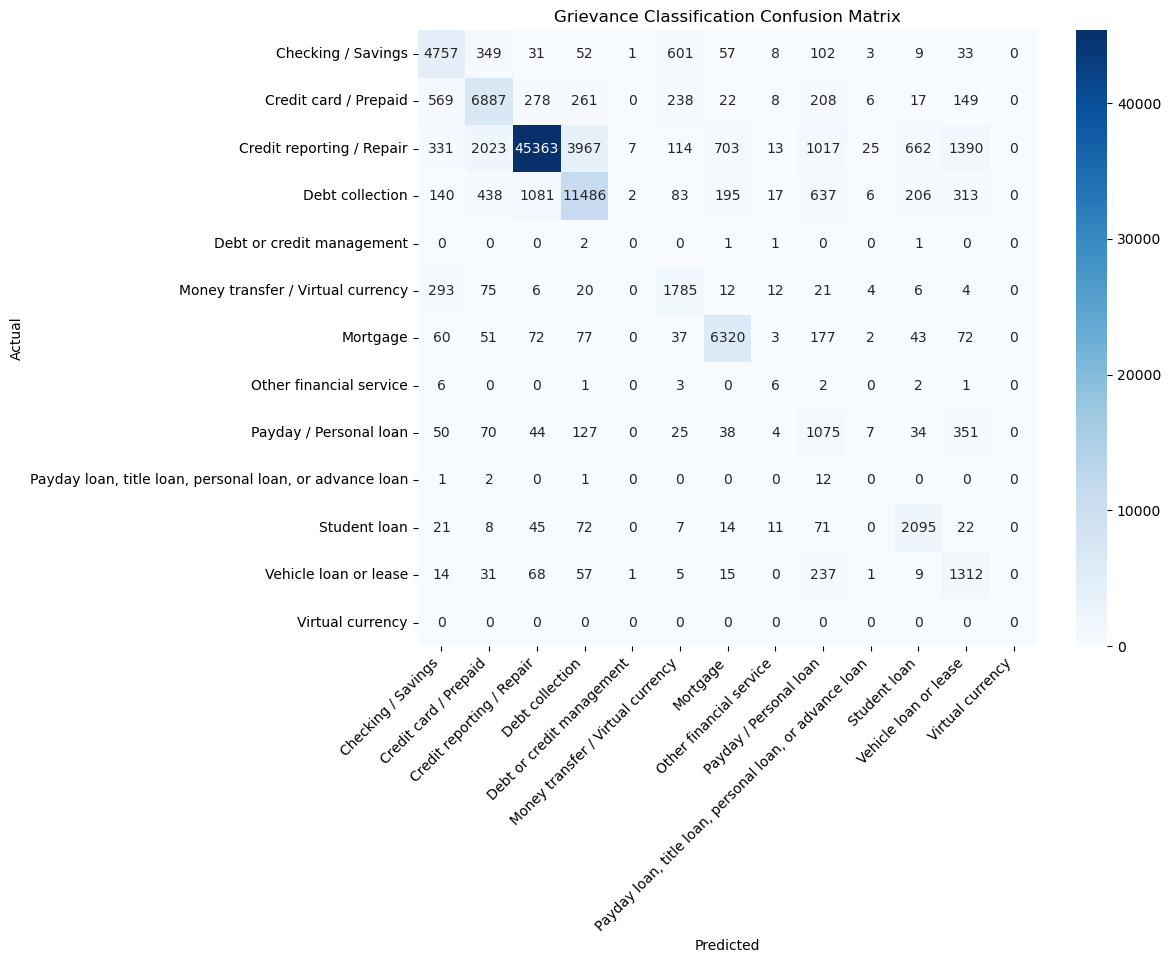

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=model.classes_, yticklabels=model.classes_, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Grievance Classification Confusion Matrix')
plt.xticks(rotation=45, ha='right')
plt.show()